In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN, HDBSCAN
from sklearn.datasets import make_blobs

In [2]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))

    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])

    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]

        class_index = (labels == k).nonzero()[0]

        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                'x' if k == -1 else 'o',
                markerfacecolor=tuple(col),
                markeredgecolor='k',
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci]
            )

    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = 'True' if ground_truth else 'Estimated'
    title = f'{preamble} number of clusters: {n_clusters_}'

    if parameters is not None:
        parameters_str = ', '.join(f'{k}={v}' for k, v in parameters.items())
        title += f' | {parameters_str}'

    ax.set_title(title)
    plt.tight_layout()

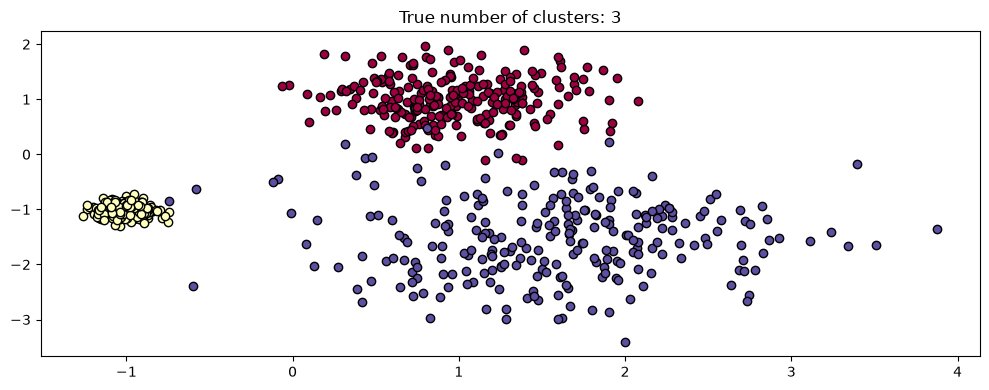

In [3]:
centers = [[1, 1], [-1, -1], [1.5, -1.5]]

X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.4, 0.1, 0.75], random_state=0
)

plot(X, labels=labels_true, ground_truth=True)
plt.show()

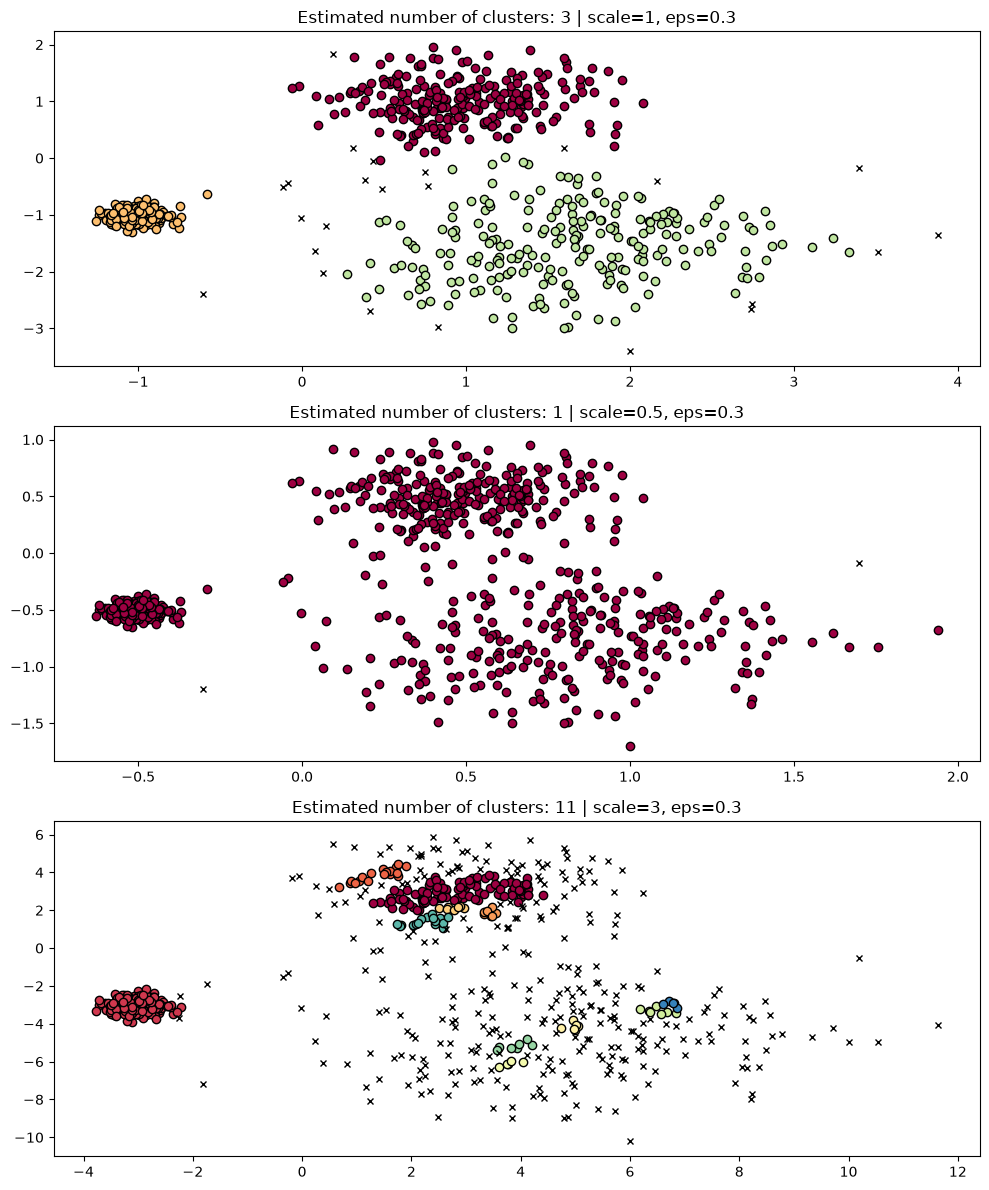

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))

dbs = DBSCAN(eps=0.3)

for idx, scale in enumerate([1, 0.5, 3]):
    dbs.fit(X * scale)

    plot(X * scale, dbs.labels_, parameters={'scale': scale, 'eps': 0.3}, ax=axes[idx])

plt.show()

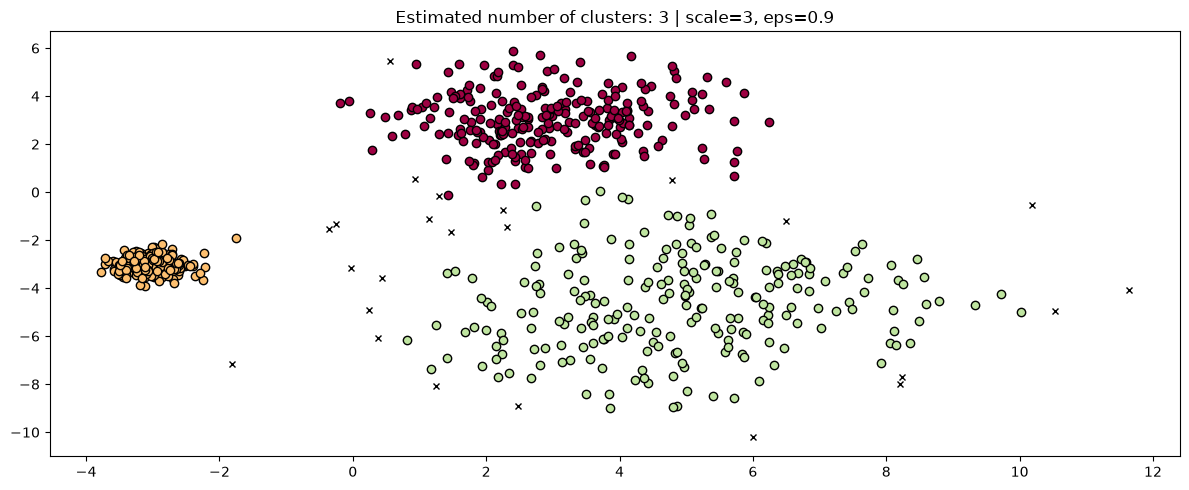

In [5]:
fig, axis = plt.subplots(1, 1, figsize=(12, 5))

dbs = DBSCAN(eps=0.9).fit(3 * X)

plot(3 * X, dbs.labels_, parameters={'scale': 3, 'eps': 0.9}, ax=axis)
plt.show()

d:\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
d:\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
d:\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


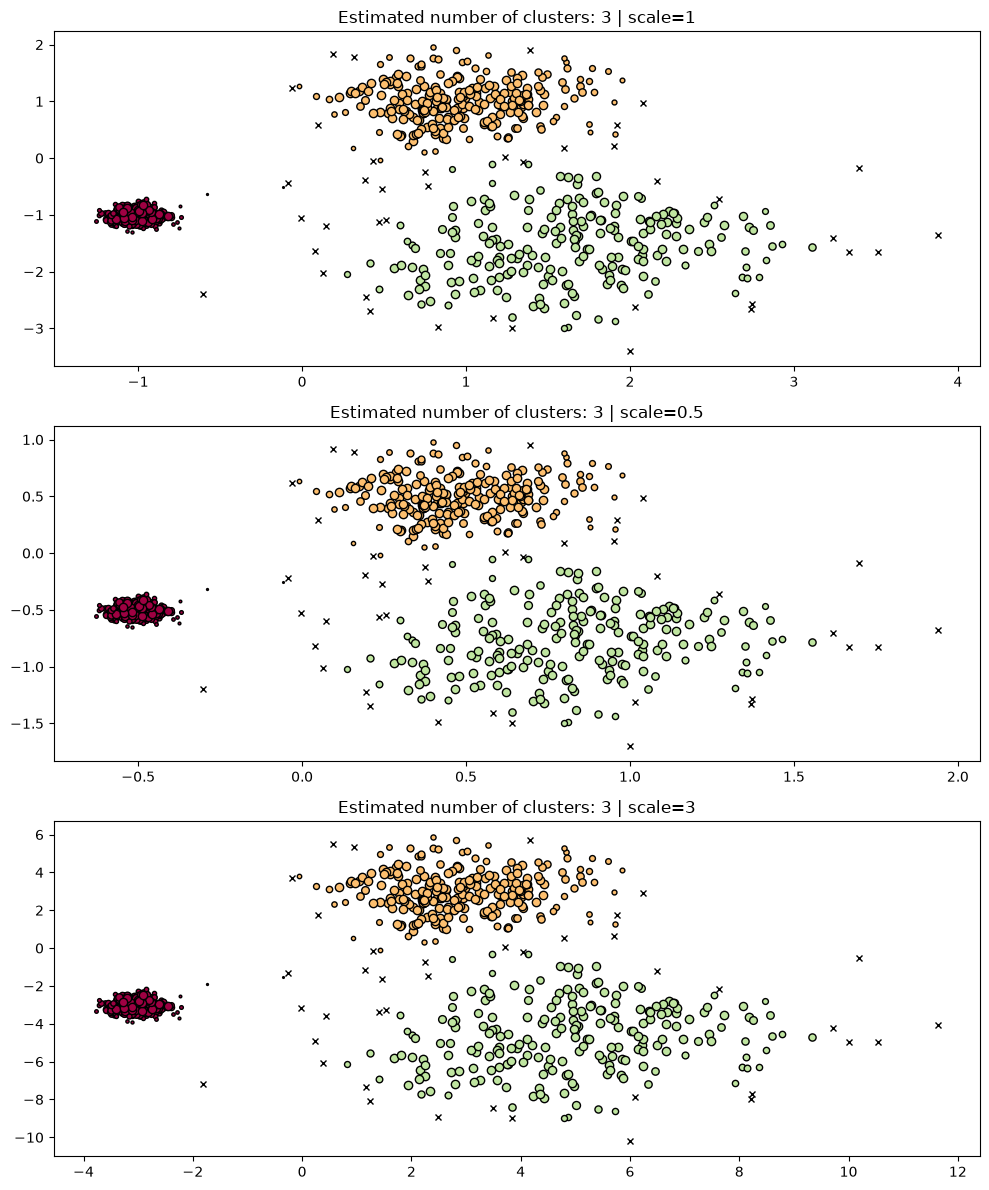

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))

hdb = HDBSCAN()

for idx, scale in enumerate([1, 0.5, 3]):
    hdb.fit(X * scale)

    plot(X * scale, hdb.labels_, hdb.probabilities_, ax=axes[idx], parameters={'scale': scale})

plt.show()

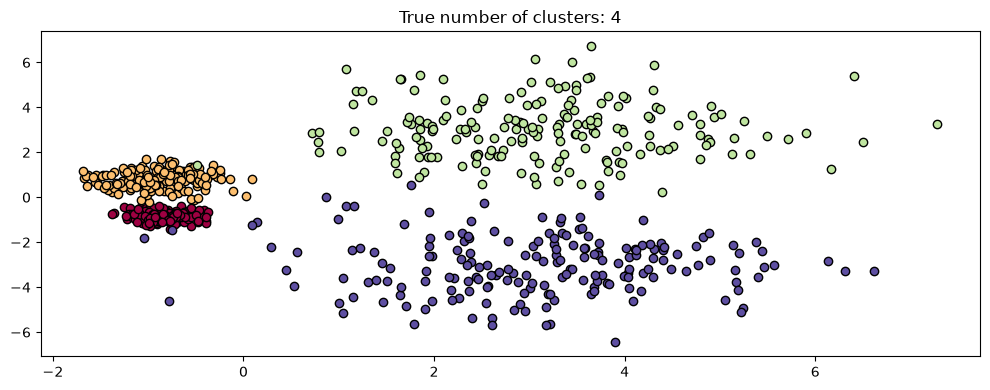

In [7]:
centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]

X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0
)

plot(X, labels=labels_true, ground_truth=True)
plt.show()

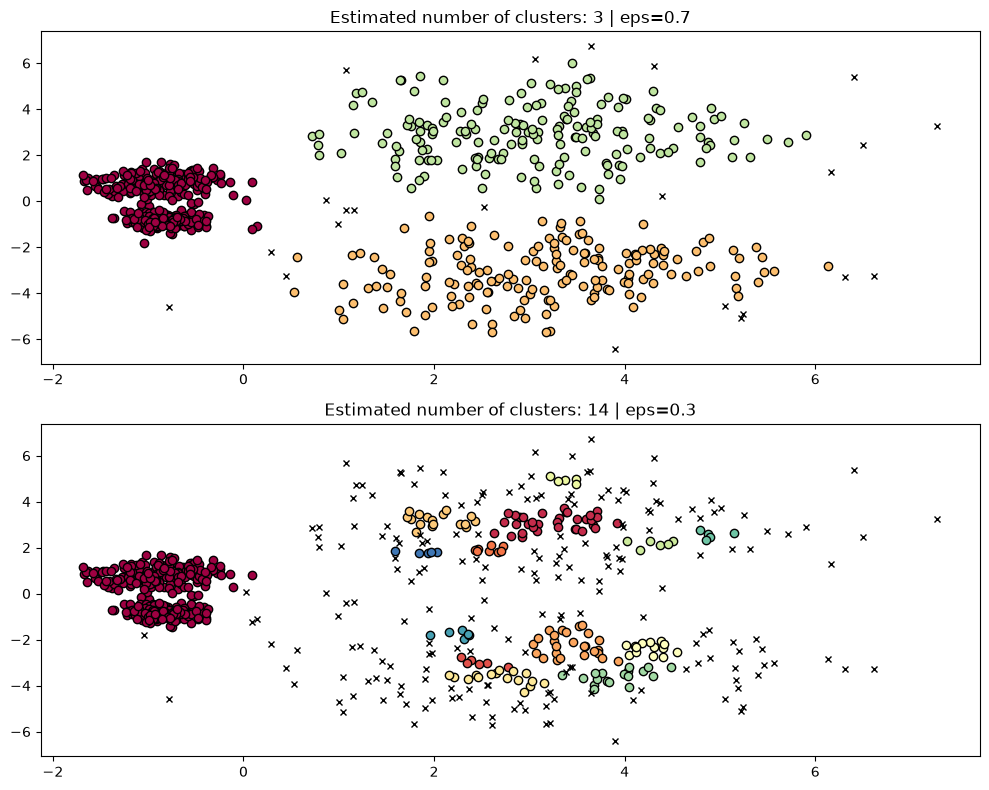

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

params = {'eps': 0.7}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[0])

params = {'eps': 0.3}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[1])

plt.show()

d:\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


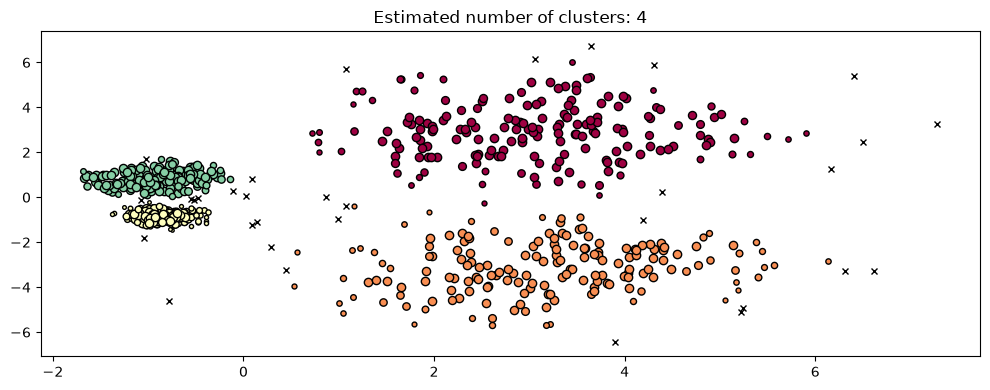

In [9]:
hdb = HDBSCAN().fit(X)

plot(X, hdb.labels_, hdb.probabilities_)
plt.show()

d:\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


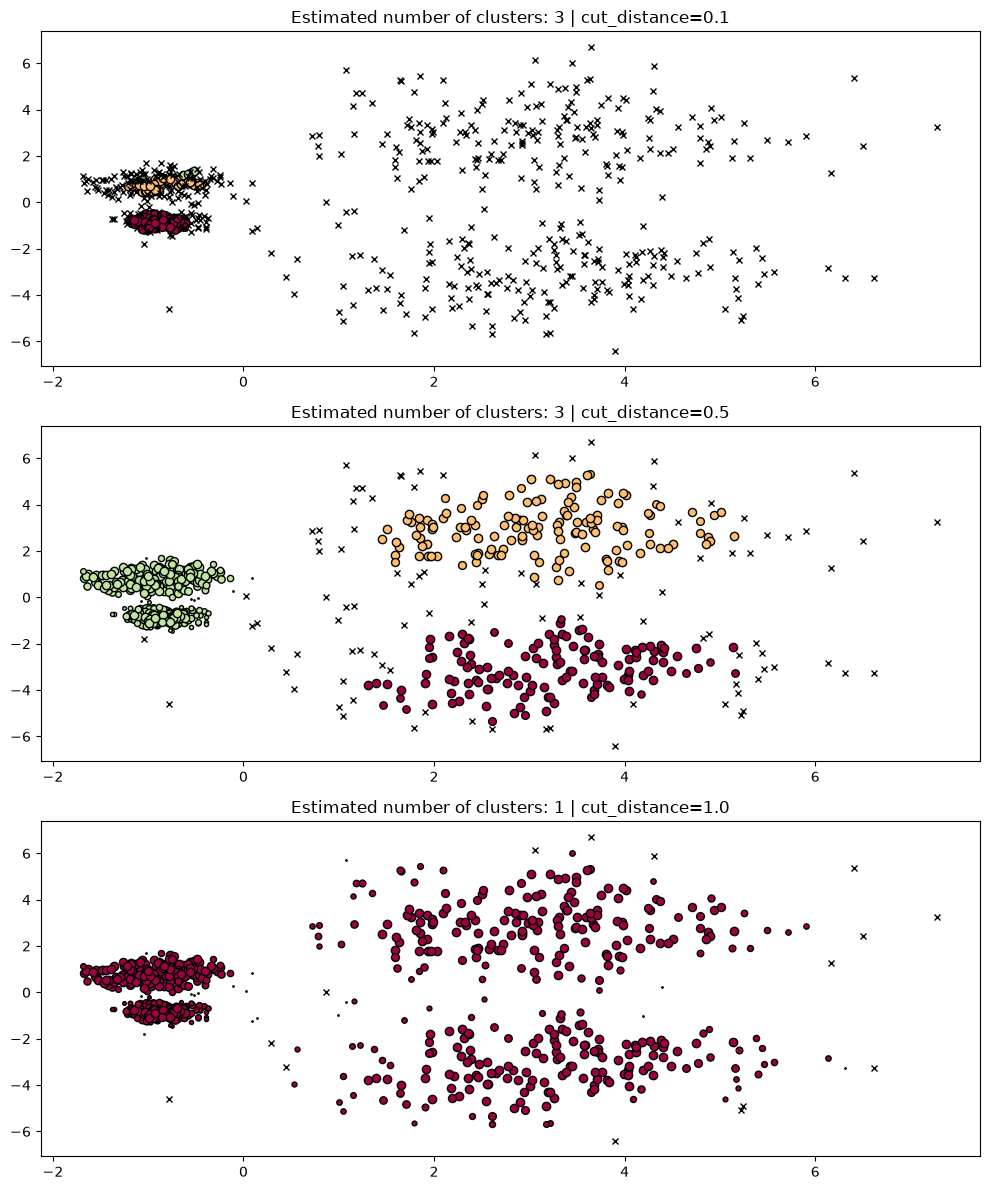

In [10]:
PARAM = ({'cut_distance': 0.1}, {'cut_distance': 0.5}, {'cut_distance': 1.0})

hdb = HDBSCAN().fit(X)

fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))

for i, param in enumerate(PARAM):
    labels = hdb.dbscan_clustering(**param)

    plot(X, labels, hdb.probabilities_, param, ax=axes[i])

plt.show()